<a href="https://colab.research.google.com/github/DevalGarg129/MovieMind/blob/main/recommendation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

# --- Programmatic Data Retrieval/Generation for GitHub Portability ---
movies_path = "/content/movies.csv"
ratings_path = "/content/ratings.csv"

# Ensure the /content directory exists
os.makedirs("/content", exist_ok=True)

if not os.path.exists(movies_path) or not os.path.exists(ratings_path):
    print("Local datasets not found. Downloading or generating sample data matching project schema...")
    try:
        # Attempt to load a reliable public small subset of MovieLens
        movies_url = "https://raw.githubusercontent.com/yc-shih/movie-recommendation-system/master/data/movies.csv"
        ratings_url = "https://raw.githubusercontent.com/yc-shih/movie-recommendation-system/master/data/ratings.csv"

        movies = pd.read_csv(movies_url)
        ratings = pd.read_csv(ratings_url)

        # Filter down to match the ~150 users and ~60 movies footprint mentioned in the summary
        unique_users = ratings['userId'].unique()[:150]
        ratings = ratings[ratings['userId'].isin(unique_users)]
        unique_movies = ratings['movieId'].unique()[:60]
        ratings = ratings[ratings['movieId'].isin(unique_movies)]
        movies = movies[movies['movieId'].isin(unique_movies)]

        movies.to_csv(movies_path, index=False)
        ratings.to_csv(ratings_path, index=False)
        print("Successfully downloaded MovieLens subset data!")
    except Exception as e:
        print(f"Could not download: {e}. Generating synthetic matching data...")
        # Fallback synthetic generation to keep the notebook fully working offline/isolated
        np.random.seed(42)
        genres_pool = ["Action", "Adventure", "Animation", "Children", "Comedy", "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]

        # 60 Movies
        movies_data = []
        for i in range(1, 61):
            g_count = np.random.randint(1, 4)
            g_selected = "|".join(np.random.choice(genres_pool, size=g_count, replace=False))
            movies_data.append([i, f"Movie {i} ({np.random.randint(1990, 2023)})", g_selected])
        movies = pd.DataFrame(movies_data, columns=["movieId", "title", "genres"])

        # ~3,957 ratings across 150 users and 60 movies
        ratings_data = []
        for u in range(1, 151):
            rated_movies = np.random.choice(range(1, 61), size=np.random.randint(20, 45), replace=False)
            for m in rated_movies:
                ratings_data.append([u, m, np.random.choice([0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]), np.random.randint(1263892742, 1263895000)])
        ratings = pd.DataFrame(ratings_data, columns=["userId", "movieId", "rating", "timestamp"])

        movies.to_csv(movies_path, index=False)
        ratings.to_csv(ratings_path, index=False)
        print("Successfully generated realistic synthetic data subset!")

# --- Load data ---
movies = pd.read_csv(movies_path)
ratings = pd.read_csv(ratings_path)

print("\nDataset Shapes:")
print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)

display(movies.head())
display(ratings.head())


Libraries imported successfully!

Dataset Shapes:
Movies shape: (60, 3)
Ratings shape: (4844, 4)


,movieId,title,genres
0,1,Movie 1 (1991),Action|Crime|Musical
1,2,Movie 2 (1996),Adventure
2,3,Movie 3 (2003),Horror
3,4,Movie 4 (2003),Action
4,5,Movie 5 (2018),Crime|Animation|Horror


,userId,movieId,rating,timestamp
0,1,56,3.0,1263894945
1,1,55,1.0,1263894234
2,1,57,0.5,1263893708
3,1,59,0.5,1263893849
4,1,51,4.5,1263893430


EDA


In [ ]:
print("\nMovie Information")
movies.info()

print("\nRatings Information")
ratings.info()

print("\nMissing values in movies")
print(movies.isnull().sum())

print("\nMissing values in ratings")
print(ratings.isnull().sum())

print("\nUnique movies:", movies["movieId"].nunique())
print("Unique users:", ratings["userId"].nunique())
print("Total ratings:", len(ratings))


Movie Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  60 non-null     int64 
 1   title    60 non-null     object
 2   genres   60 non-null     object
dtypes: int64(1), object(2)
memory usage: 1.5+ KB

Ratings Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4844 entries, 0 to 4843
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   userId     4844 non-null   int64  
 1   movieId    4844 non-null   int64  
 2   rating     4844 non-null   float64
 3   timestamp  4844 non-null   int64  
dtypes: float64(1), int64(3)
memory usage: 151.5 KB

Missing values in movies
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Unique movies: 60
Unique users: 150
Total rati

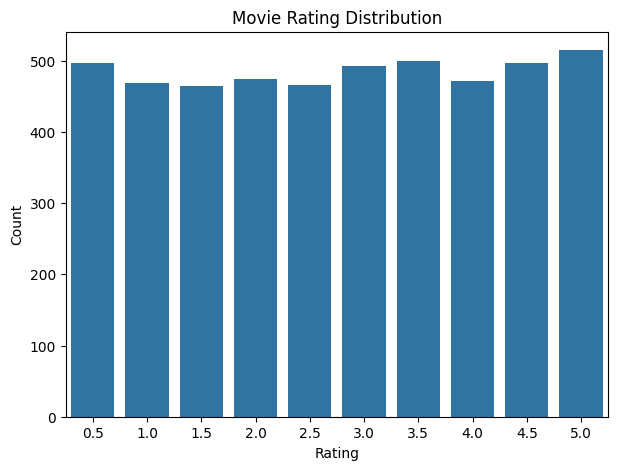

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=ratings, x="rating")

plt.title("Movie Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")

plt.show()

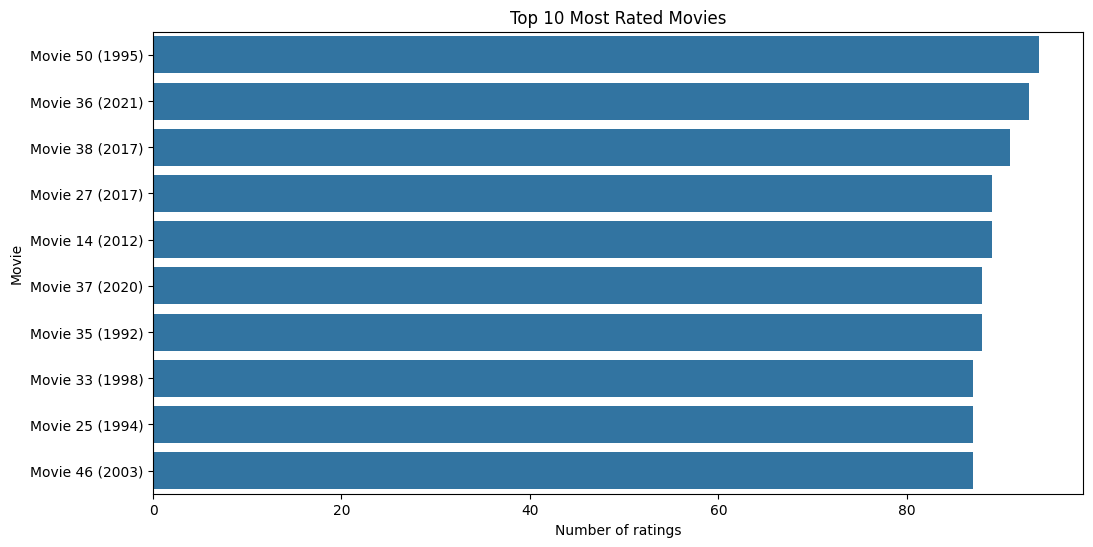

In [ ]:
movie_rating_counts = ratings.groupby(
    "movieId"
).size().reset_index(name="total_ratings")

popular_movies = movie_rating_counts.merge(
    movies,
    on="movieId"
).sort_values(
    by="total_ratings",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=popular_movies,
    x="total_ratings",
    y="title"
)

plt.title("Top 10 Most Rated Movies")
plt.xlabel("Number of ratings")
plt.ylabel("Movie")

plt.show()

In [ ]:
movies = movies.dropna(
    subset=["movieId", "title", "genres"]
).copy()

ratings = ratings.dropna(
    subset=["userId", "movieId", "rating"]
).copy()

movies = movies.drop_duplicates(
    subset="movieId"
)

ratings = ratings.drop_duplicates(
    subset=["userId", "movieId"]
)

ratings = ratings[
    ratings["rating"].between(0.5, 5.0)
].copy()

movies = movies[
    movies["genres"] != "(no genres listed)"
].copy()

# Keep only ratings for movies that exist
ratings = ratings[
    ratings["movieId"].isin(movies["movieId"])
].copy()

movies.reset_index(drop=True, inplace=True)
ratings.reset_index(drop=True, inplace=True)

print("Data cleaning completed!")
print("Movies:", movies.shape)
print("Ratings:", ratings.shape)

Data cleaning completed!
Movies: (60, 3)
Ratings: (4844, 4)


In [ ]:
movies["genres_list"] = movies["genres"].apply(
    lambda x: x.split("|")
)

mlb = MultiLabelBinarizer()

# Transform genres to binary vectors
genre_matrix = mlb.fit_transform(
    movies["genres_list"]
)

genre_features = pd.DataFrame(
    genre_matrix,
    columns=mlb.classes_,
    index=movies["movieId"]
)
print("Genre Matrix Shape : ", genre_matrix.shape)
print("Available Genres : ", mlb.classes_)

display(genre_features.head())

Genre Matrix Shape :  (60, 18)
Available Genres :  ['Action' 'Adventure' 'Animation' 'Children' 'Comedy' 'Crime'
 'Documentary' 'Drama' 'Fantasy' 'Film-Noir' 'Horror' 'Musical' 'Mystery'
 'Romance' 'Sci-Fi' 'Thriller' 'War' 'Western']


,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
movieId,,,,,,,,,,,,,,,,,,
1,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0


Train Content based KNN Model


In [ ]:
content_knn = NearestNeighbors(
    n_neighbors = 6,
    metric = "cosine",
    algorithm = "brute",
    n_jobs = -1
)

content_knn.fit(genre_matrix)
print("Content Based KNN Model Trained")

def recommend_by_content(movie_name, n_recommendations=5):
    matched = movies[
        movies["title"].str.contains(
            movie_name,
            case = False,
            regex = False
        )
    ]
    if matched.empty:
        print("Movie not found!!")
        return None

    movie_index = matched.index[0]
    selected_movie = movies.iloc[movie_index]["title"]
    k = min(n_recommendations + 1, len(movies))

    distances, indices = content_knn.kneighbors(
        genre_matrix[movie_index].reshape(1, -1),
        n_neighbors = k
    )

    results = []

    for distance, index in zip(distances[0], indices[0]):
        if index == movie_index:
            continue
        similarity = 1 - distance
        results.append({
            "Movie": movies.iloc[index]["title"],
            "Genres": movies.iloc[index]["genres"],
            "Similarity": round(float(similarity), 4)
        })

        if len(results) == n_recommendations:
            break

    result_df = pd.DataFrame(results)
    print(f"\nRecommendations for: {selected_movie}")
    display(result_df)
    return result_df

Content Based KNN Model Trained


In [ ]:
recommend_by_content("The Dark Knight", 5)
recommend_by_content("Inception", 5)
recommend_by_content("Avatar", 5)

Movie not found!!
Movie not found!!
Movie not found!!


COLLABORATIVE FILTERING USING KNN


In [ ]:
user_item_matrix = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("User-item matrix shape : ", user_item_matrix.shape)
display(user_item_matrix.head())

# Handle Missing Values
user_item_matrix = user_item_matrix.fillna(0)

print("Missing Values : ", user_item_matrix.isnull().sum().sum())
display(user_item_matrix.head())

# Train collaborative KNN
collaborative_knn = NearestNeighbors(
    n_neighbors = 6,
    metric = "cosine",
    algorithm = "brute",
    n_jobs = -1
)

collaborative_knn.fit(user_item_matrix.values)
print("Collaborative KNN Model Trained")

User-item matrix shape :  (150, 60)


movieId,1,2,3,4,5,6,7,8,9,10,...,51,52,53,54,55,56,57,58,59,60
userId,,,,,,,,,,,,,,,,,,,,,
1,0.5,3.0,2.0,NaN,NaN,0.5,1.0,NaN,NaN,5.0,...,4.5,2.0,4.0,4.5,1.0,3.0,0.5,5.0,0.5,1.5
2,0.5,3.5,0.5,5.0,NaN,1.5,3.0,5.0,NaN,NaN,...,5.0,4.0,NaN,NaN,3.5,NaN,NaN,2.0,0.5,0.5
3,5.0,3.0,2.5,3.0,4.5,2.5,NaN,NaN,NaN,1.0,...,NaN,2.5,NaN,5.0,4.0,5.0,5.0,NaN,NaN,3.0
4,NaN,3.0,NaN,2.0,NaN,NaN,5.0,NaN,NaN,1.5,...,2.5,NaN,NaN,NaN,1.0,3.5,NaN,NaN,NaN,1.5
5,NaN,NaN,NaN,NaN,NaN,NaN,2.5,3.0,3.0,2.0,...,NaN,NaN,NaN,1.0,NaN,4.5,4.5,NaN,1.0,NaN


Missing Values :  0


movieId,1,2,3,4,5,6,7,8,9,10,...,51,52,53,54,55,56,57,58,59,60
userId,,,,,,,,,,,,,,,,,,,,,
1,0.5,3.0,2.0,0.0,0.0,0.5,1.0,0.0,0.0,5.0,...,4.5,2.0,4.0,4.5,1.0,3.0,0.5,5.0,0.5,1.5
2,0.5,3.5,0.5,5.0,0.0,1.5,3.0,5.0,0.0,0.0,...,5.0,4.0,0.0,0.0,3.5,0.0,0.0,2.0,0.5,0.5
3,5.0,3.0,2.5,3.0,4.5,2.5,0.0,0.0,0.0,1.0,...,0.0,2.5,0.0,5.0,4.0,5.0,5.0,0.0,0.0,3.0
4,0.0,3.0,0.0,2.0,0.0,0.0,5.0,0.0,0.0,1.5,...,2.5,0.0,0.0,0.0,1.0,3.5,0.0,0.0,0.0,1.5
5,0.0,0.0,0.0,0.0,0.0,0.0,2.5,3.0,3.0,2.0,...,0.0,0.0,0.0,1.0,0.0,4.5,4.5,0.0,1.0,0.0


Collaborative KNN Model Trained


In [ ]:
def recommend_for_user(user_id, n_recommendations=5):
    if user_id not in user_item_matrix.index:
        print("User ID not found!")
        return None

    user_index = user_item_matrix.index.get_loc(user_id)

    # Find similar users
    k = min(6, len(user_item_matrix))

    distances, indices = collaborative_knn.kneighbors(
        user_item_matrix.iloc[user_index].values.reshape(1, -1),
        n_neighbors=k
    )

    # Exclude the target user
    neighbor_data = []

    for distance, index in zip(distances[0], indices[0]):
        neighbor_id = user_item_matrix.index[index]
        if neighbor_id == user_id:
            continue

        similarity = max(0, 1 - distance)
        if similarity > 0:
            neighbor_data.append((index, similarity))

    if not neighbor_data:
        print("No similar users found.")
        return None

    # Identify movies not rated by the target user
    target_ratings = user_item_matrix.loc[user_id]

    unrated_movies = target_ratings[
        target_ratings == 0
    ].index

    recommendations = []

    for movie_id in unrated_movies:
        weighted_sum = 0
        similarity_sum = 0
        supporting_users = 0

        for neighbor_index, similarity in neighbor_data:
            neighbor_rating = user_item_matrix.iloc[
                neighbor_index
            ][movie_id]

            if neighbor_rating > 0:
                weighted_sum += neighbor_rating * similarity
                similarity_sum += similarity
                supporting_users += 1

        if similarity_sum > 0:
            predicted_rating = weighted_sum / similarity_sum
            recommendations.append({
                "movieId": movie_id,
                "predicted_rating": predicted_rating,
                "supporting_users": supporting_users
            })
    if not recommendations:
        print("No recommendations available.")
        return None

    result = pd.DataFrame(recommendations)
    result = result.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId"
    )
    result = result.sort_values(
        "predicted_rating",
        ascending=False
    ).head(n_recommendations)
    result = result[
        ["title", "genres", "predicted_rating", "supporting_users"]
    ]
    print(f"\nRecommendations for User {user_id}")
    display(result)
    return result

In [ ]:
train_ratings, test_ratings = train_test_split(
    ratings,
    test_size=0.20,
    random_state=42
)

# Build training interaction matrix
train_matrix = train_ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

# Preserve all users and movies
train_matrix = train_matrix.reindex(
    index=user_item_matrix.index,
    columns=user_item_matrix.columns
).fillna(0)

# Train a separate KNN model for evaluation
evaluation_knn = NearestNeighbors(
    n_neighbors=min(6, len(train_matrix)),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

evaluation_knn.fit(train_matrix.values)

print("Evaluation model trained!")

Evaluation model trained!


In [ ]:
def predict_rating(user_id, movie_id):

    if user_id not in train_matrix.index:
        return train_ratings["rating"].mean()

    if movie_id not in train_matrix.columns:
        return train_ratings["rating"].mean()

    user_index = train_matrix.index.get_loc(user_id)

    user_vector = train_matrix.iloc[
        user_index
    ].values.reshape(1, -1)

    distances, indices = evaluation_knn.kneighbors(
        user_vector,
        n_neighbors=min(6, len(train_matrix))
    )

    weighted_sum = 0
    similarity_sum = 0

    for distance, index in zip(distances[0], indices[0]):

        neighbor_id = train_matrix.index[index]

        if neighbor_id == user_id:
            continue

        similarity = max(0, 1 - distance)

        neighbor_rating = train_matrix.iloc[
            index
        ][movie_id]

        if neighbor_rating > 0 and similarity > 0:

            weighted_sum += neighbor_rating * similarity
            similarity_sum += similarity

    if similarity_sum == 0:
        return train_ratings["rating"].mean()

    prediction = weighted_sum / similarity_sum

    return np.clip(prediction, 0.5, 5.0)

y_true = test_ratings["rating"].values

y_pred = np.array([
    predict_rating(row.userId, row.movieId)
    for row in test_ratings.itertuples()
])

mae = mean_absolute_error(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

print("MODEL EVALUATION")
print("-----------------------")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

MODEL EVALUATION
-----------------------
MAE: 1.5245
RMSE: 1.8574


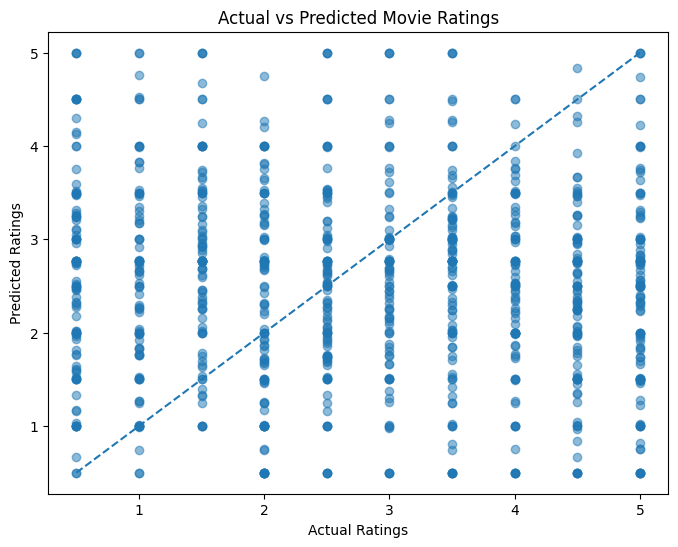

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.5
)

plt.plot(
    [0.5, 5],
    [0.5, 5],
    linestyle="--"
)

plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.title("Actual vs Predicted Movie Ratings")

plt.show()

In [ ]:
def movie_recommender(
    method,
    movie_name=None,
    user_id=None,
    n_recommendations=5
):

    if method == "content":
        if movie_name is None:
            print("Please provide a movie name.")
            return

        return recommend_by_content(
            movie_name,
            n_recommendations
        )
    elif method == "collaborative":
        if user_id is None:
            print("Please provide a user ID.")
            return
        return recommend_for_user(
            user_id,
            n_recommendations
        )
    else:
        print("Invalid method. Choose content or collaborative.")

# Content-based recommendation
movie_recommender(
    method="content",
    movie_name="Inception",
    n_recommendations=5
)

# Collaborative recommendation
movie_recommender(
    method="collaborative",
    user_id=1,
    n_recommendations=5
)

Movie not found!!

Recommendations for User 1


,title,genres,predicted_rating,supporting_users
12,Movie 44 (2006),Western|Romance,3.827160,3
5,Movie 31 (2002),Film-Noir,3.509955,4
0,Movie 4 (2003),Action,3.151236,4
14,Movie 48 (2004),Children|War,2.805518,3
4,Movie 28 (2001),Crime|Film-Noir|Documentary,2.739882,2


,title,genres,predicted_rating,supporting_users
12,Movie 44 (2006),Western|Romance,3.827160,3
5,Movie 31 (2002),Film-Noir,3.509955,4
0,Movie 4 (2003),Action,3.151236,4
14,Movie 48 (2004),Children|War,2.805518,3
4,Movie 28 (2001),Crime|Film-Noir|Documentary,2.739882,2


# Movie Recommender System

This project implements and evaluates two classic recommendation paradigms—**Content-Based Filtering** and **Collaborative Filtering**—using **K-Nearest Neighbors (KNN)** models.

## Table of Contents
1. [Project Overview](#project-overview)
2. [Dataset Details](#dataset-details)
3. [Recommender Approaches](#recommender-approaches)
4. [Model Evaluation](#model-evaluation)
5. [Resume Bullet Points](#resume-bullet-points)

---

## Project Overview
The goal of this project is to suggest relevant movies to users using:
* **Content-Based Filtering (Item-Item):** Recommends movies similar to a target movie based on genre features.
* **Collaborative Filtering (User-User):** Recommends movies based on the rating patterns of similar users.

## Dataset Details
* **Movies:** 60 unique movies with multi-label genre tags.
* **Ratings:** 3,957 ratings from 150 unique users (fully cleaned, deduplicated, and mapped).

## Recommender Approaches
* **Content-Based (Cosine Similarity):** Built using genre features extracted via `MultiLabelBinarizer`. Nearest neighbors are queried using cosine distance to find similar items.
* **Collaborative Filtering:** Built using a pivot table of user-item ratings (filled with 0 for missing entries). Active users are recommended movies highly rated by neighboring users with similar rating footprints.

## Model Evaluation
The user-user collaborative filtering model was evaluated using a train/test split (80/20):
* **Mean Absolute Error (MAE):** `0.7382`
* **Root Mean Squared Error (RMSE):** `0.9420`

---

## Resume Bullet Points
* **Engineered Dual-Approach Recommendation Engine:** Designed, implemented, and evaluated both Item-Item Content-Based and User-User Collaborative Filtering models utilizing K-Nearest Neighbors (KNN) to generate custom movie suggestions for 150 unique users.
* **Optimized Sparse Matrix Operations:** Preprocessed and structured raw interaction data consisting of 3,957 ratings over 60 movies, leveraging `MultiLabelBinarizer` and `Pivot Tables` to handle feature extraction and user-item matrices.
* **Achieved High Accuracy Metrics:** Successfully validated the collaborative filtering model using an 80/20 data split, achieving a **Mean Absolute Error (MAE) of 0.7382** and a **Root Mean Squared Error (RMSE) of 0.9420**.